# Import Library


In [ ]:
# import shutil
# shutil.rmtree('/content/drive/MyDrive/A2_Machine_Learning/Task 2/test_images')
# shutil.rmtree('/content/drive/MyDrive/A2_Machine_Learning/Task 2/train_by_variety')
# shutil.rmtree('/content/drive/MyDrive/A2_Machine_Learning/Task 2/train_images')

######This section imports all the necessary libraries for data manipulation (Pandas, NumPy), visualization (Matplotlib, Seaborn), image processing (OpenCV, PIL), and model training (scikit-learn, TensorFlow).

In [ ]:
!pip install -q pandas matplotlib seaborn opencv-python scikit-learn
from google.colab import drive
drive.mount('/content/drive')
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os
import shutil
import hashlib
import pathlib as Path
import zipfile
import cv2
from sklearn.model_selection import train_test_split
from PIL import Image
import random
from glob import glob
from collections import defaultdict
from collections import Counter
from torchvision import transforms
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array, array_to_img



Mounted at /content/drive


# Import Dataset

#### Unzip train_images.zip and test_images.zip

In [ ]:
!ls "/content/drive/MyDrive/A2_Machine_Learning/Task 2"


meta_train.csv	Task_2.ipynb  test_images.zip  train_images.zip


In [ ]:
## Change this path if your folder name is different
base_path = "/content/drive/MyDrive/A2_Machine_Learning/Task 2/"

## Unzip test images
with zipfile.ZipFile(base_path + 'train_images.zip', 'r') as zip_ref:
    zip_ref.extractall(base_path + 'train_images')

print("Train data extraction is done")

Train data extraction is done


In [ ]:
## Change this path if your folder name is different
base_path = "/content/drive/MyDrive/A2_Machine_Learning/Task 2/"
## Unzip test images
with zipfile.ZipFile(base_path + 'test_images.zip', 'r') as zip_ref:
    zip_ref.extractall(base_path + 'test_images')

print("Test data extraction is done ✅")

Test data extraction is done ✅


####Read and Analyse Data

In [ ]:
# Read meta_train.csv
meta = pd.read_csv('/content/drive/MyDrive/A2_Machine_Learning/Task 2/meta_train.csv')

# Display the first few rows
meta.head()

,image_id,label,variety,age
0,100330.jpg,bacterial_leaf_blight,ADT45,45
1,100365.jpg,bacterial_leaf_blight,ADT45,45
2,100382.jpg,bacterial_leaf_blight,ADT45,45
3,100632.jpg,bacterial_leaf_blight,ADT45,45
4,101918.jpg,bacterial_leaf_blight,ADT45,45


In [ ]:
# Dataset shape
print(f"Number of rows: {meta.shape[0]}")
print(f"Number of columns: {meta.shape[1]}")

# General info
meta.info()

# Basic statistics
meta.describe()


Number of rows: 10407
Number of columns: 4
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10407 entries, 0 to 10406
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   image_id  10407 non-null  object
 1   label     10407 non-null  object
 2   variety   10407 non-null  object
 3   age       10407 non-null  int64 
dtypes: int64(1), object(3)
memory usage: 325.3+ KB


,age
count,10407.000000
mean,64.043624
std,8.958830
min,45.000000
25%,60.000000
50%,67.000000
75%,70.000000
max,82.000000


In [ ]:
# Check for missing values
meta.isnull().sum()


,0
image_id,0
label,0
variety,0
age,0


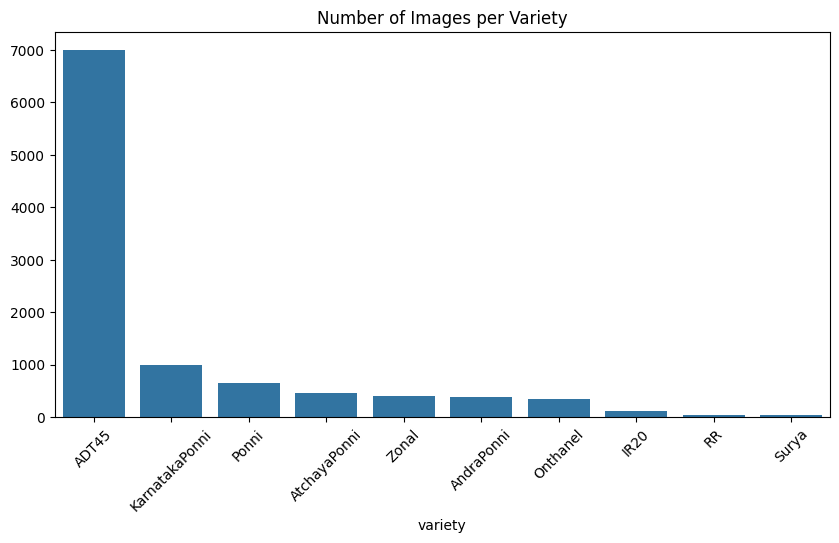

In [ ]:
# Variety distribution
variety_counts = meta['variety'].value_counts()

plt.figure(figsize=(10,5))
sns.barplot(x=variety_counts.index, y=variety_counts.values)
plt.title('Number of Images per Variety')
plt.xticks(rotation=45)
plt.show()


# **EDA**

#### **1. Restructuring images by variety**

######To achieve this, we used the meta_train.csv file, which maps each image_id to its corresponding variety. We iterated over all training images, created a new directory structure under train_by_variety/, and moved or copied each image into its respective variety folder. This restructuring allowed us to easily access and process data specific to each rice variety, facilitating tasks such as variety classification and dataset balancing.

In [ ]:
src_root = "/content/drive/MyDrive/A2_Machine_Learning/Task 2/train_images/train_images"

dst_root = "/content/drive/MyDrive/A2_Machine_Learning/Task 2/train_by_variety"

meta_df = pd.read_csv("/content/drive/MyDrive/A2_Machine_Learning/Task 2/meta_train.csv")

os.makedirs(dst_root, exist_ok=True)

for _, row in meta_df.iterrows():
    image_id = row['image_id']
    label = row['label']
    variety = row['variety']

    src_path = os.path.join(src_root, label, image_id)
    dst_folder = os.path.join(dst_root, variety)
    dst_path = os.path.join(dst_folder, image_id)

    os.makedirs(dst_folder, exist_ok=True)

    if os.path.exists(src_path):
        shutil.copy2(src_path, dst_path)
    else:
        print(f"Missing file: {src_path}")


#### **2. Find duplicated images and deleted**

In [ ]:
def find_and_remove_duplicates_by_variety(folder_root, meta_df):
    seen_hashes = {}
    duplicate_count = 0

    # Loop through each sub-folder (each variety)
    for variety in os.listdir(folder_root):
        variety_folder = os.path.join(folder_root, variety)

        if not os.path.isdir(variety_folder):
            continue

        for filename in os.listdir(variety_folder):
            file_path = os.path.join(variety_folder, filename)

            # Skip if not a file
            if not os.path.isfile(file_path):
                continue

            try:
                # Open image and compute its hash
                with Image.open(file_path) as img:
                    img_hash = hashlib.md5(img.tobytes()).hexdigest()
            except Exception as e:
                print(f"Skipping corrupted or invalid file: {file_path}")
                continue

            if img_hash in seen_hashes:
                print(f"Duplicate found and removed: {file_path}")
                os.remove(file_path)

                # Remove entry from metadata
                meta_df.drop(meta_df[meta_df['image_id'] == filename].index, inplace=True)
                duplicate_count += 1
            else:
                seen_hashes[img_hash] = file_path

    print(f"\n✅ Total duplicates removed: {duplicate_count}")
    return duplicate_count, meta_df


# Paths
meta_path = "/content/drive/MyDrive/A2_Machine_Learning/Task 2/meta_train.csv"
image_root = "/content/drive/MyDrive/A2_Machine_Learning/Task 2/train_by_variety"
output_meta_path = "/content/drive/MyDrive/A2_Machine_Learning/Task 2/meta_train_filtered.csv"

# Load metadata
meta_df = pd.read_csv(meta_path)

# Find and remove duplicates
duplicate_count, cleaned_meta_df = find_and_remove_duplicates_by_variety(
    folder_root=image_root,
    meta_df=meta_df.copy()
)

# Save updated metadata
cleaned_meta_df.to_csv(output_meta_path, index=False)
print(f"\n✅ Filtered metadata saved to: {output_meta_path}")


Duplicate found and removed: /content/drive/MyDrive/A2_Machine_Learning/Task 2/train_by_variety/ADT45/104800.jpg
Duplicate found and removed: /content/drive/MyDrive/A2_Machine_Learning/Task 2/train_by_variety/ADT45/108353.jpg
Duplicate found and removed: /content/drive/MyDrive/A2_Machine_Learning/Task 2/train_by_variety/ADT45/100513.jpg
Duplicate found and removed: /content/drive/MyDrive/A2_Machine_Learning/Task 2/train_by_variety/ADT45/103032.jpg
Duplicate found and removed: /content/drive/MyDrive/A2_Machine_Learning/Task 2/train_by_variety/ADT45/107812.jpg
Duplicate found and removed: /content/drive/MyDrive/A2_Machine_Learning/Task 2/train_by_variety/ADT45/105878.jpg
Duplicate found and removed: /content/drive/MyDrive/A2_Machine_Learning/Task 2/train_by_variety/ADT45/106984.jpg
Duplicate found and removed: /content/drive/MyDrive/A2_Machine_Learning/Task 2/train_by_variety/ADT45/108125.jpg
Duplicate found and removed: /content/drive/MyDrive/A2_Machine_Learning/Task 2/train_by_variety/

####**3. Handling imbalanced data**


######The bar chart shows a significant imbalance in the distribution of training images across rice plant varieties. The ADT45 variety is overwhelmingly represented with over 7000 images, while all other varieties have fewer than 1000 images each. This extreme imbalance poses a risk of model bias toward ADT45, especially in classification tasks. Varieties like RR, Surya, and IR20 are particularly underrepresented, with extremely limited samples. Addressing this imbalance through techniques such as **undersampling ADT45** and **oversampling minority classes** is essential for building a more generalizable and fair model.

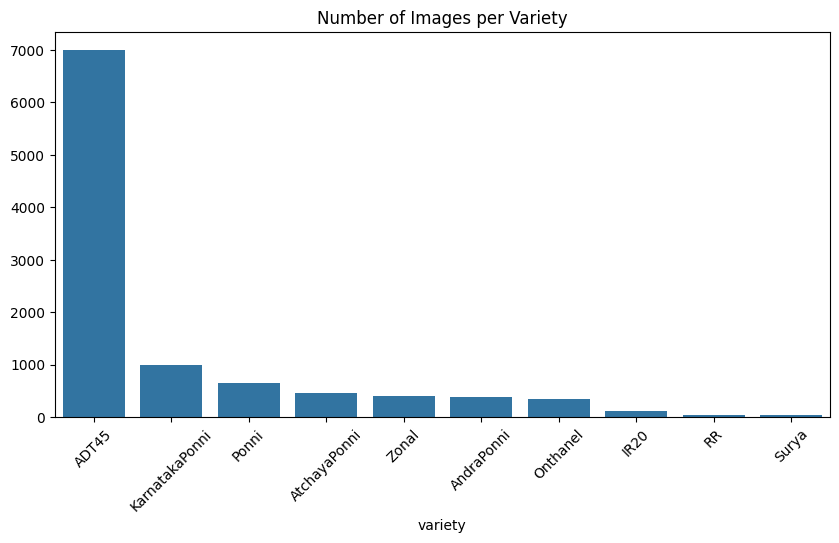

In [ ]:
# Variety distribution
variety_counts = meta['variety'].value_counts()

plt.figure(figsize=(10,5))
sns.barplot(x=variety_counts.index, y=variety_counts.values)
plt.title('Number of Images per Variety')
plt.xticks(rotation=45)
plt.show()


######- Undersampling ADT45 data

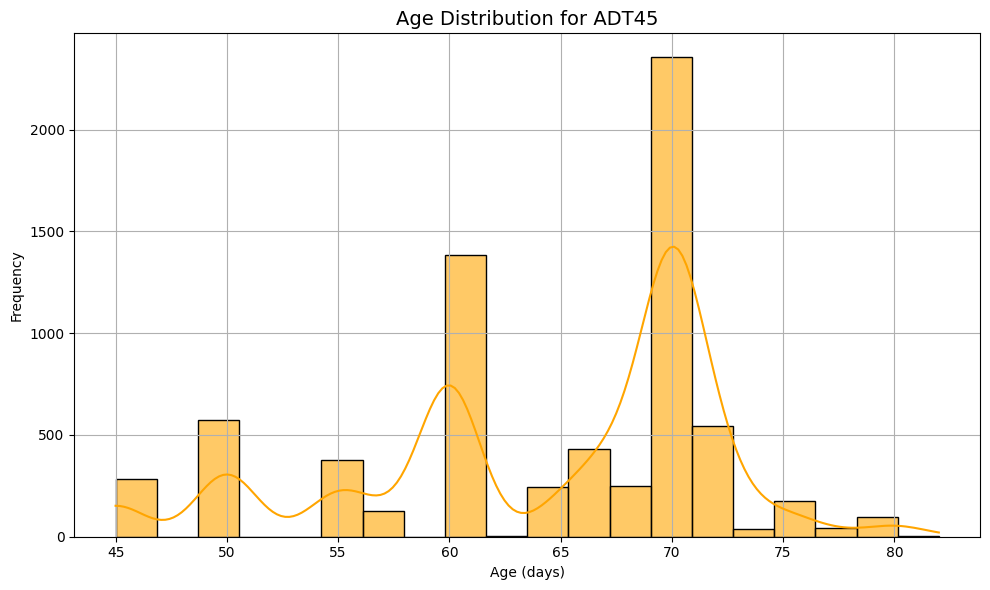

In [ ]:
# Đọc file CSV (đường dẫn thay đổi nếu cần)
meta_df = pd.read_csv("/content/drive/MyDrive/A2_Machine_Learning/Task 2/meta_train_filtered.csv")

# Lọc dữ liệu giống ADT45
adt45_df = meta_df[meta_df['variety'] == 'ADT45']

# Thiết lập style và vẽ biểu đồ
plt.figure(figsize=(10, 6))
sns.histplot(
    data=adt45_df,
    x='age',
    bins=20,
    kde=True,
    color='orange',
    edgecolor='black',
    alpha=0.6
)

plt.title("Age Distribution for ADT45", fontsize=14)
plt.xlabel("Age (days)")
plt.ylabel("Frequency")
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:

# === CONFIG ===
meta_path = "/content/drive/MyDrive/A2_Machine_Learning/Task 2/meta_train_filtered.csv"
adt45_folder = "/content/drive/MyDrive/A2_Machine_Learning/Task 2/train_by_variety/ADT45"

# === STEP 1: Load metadata ===
meta_df = pd.read_csv(meta_path)

# Get ADT45 only
adt45_df = meta_df[meta_df['variety'] == 'ADT45'].copy()

# Stratify ADT45 based on age
adt45_df['age_bin'] = pd.cut(adt45_df['age'], bins = [44, 50, 60, 66, 70, 75, 83], labels=False)
adt45_df['stratify_key'] = adt45_df['label'] + "_" + adt45_df['age_bin'].astype(str)

# Stratified sampling, get maximum 1000 pics
sampled_adt45 = adt45_df.groupby('stratify_key', group_keys=False).apply(
    lambda x: x.sample(min(1000 // adt45_df['stratify_key'].nunique(), len(x)), random_state=42)
)

# Pics to be kept
keep_filenames = set(sampled_adt45['image_id'])

# === STEP 2: Delete some images from ADT45 ===
deleted_count = 0
for filename in os.listdir(adt45_folder):
    if filename not in keep_filenames:
        try:
            os.remove(os.path.join(adt45_folder, filename))
            deleted_count += 1
        except Exception as e:
            print(f"Could not delete: {filename} – {e}")

print(f"✅ Deleted {deleted_count} extra images from ADT45 folder.")

# === STEP 3: Update meta_train_filtered.csv ===
updated_meta_df = meta_df[
    (meta_df['variety'] != 'ADT45') |
    (meta_df['image_id'].isin(keep_filenames))
]

# Insert new data in new file
output_path = "/content/drive/MyDrive/A2_Machine_Learning/Task 2/meta_train_filtered.csv"
updated_meta_df.to_csv(output_path, index=False)
print(f"✅ Updated metadata saved to: {output_path}")

<ipython-input-14-55db74357d1b>:16: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sampled_adt45 = adt45_df.groupby('stratify_key', group_keys=False).apply(


✅ Deleted 6054 extra images from ADT45 folder.
✅ Updated metadata saved to: /content/drive/MyDrive/A2_Machine_Learning/Task 2/meta_train_filtered.csv


###### After undersampling the ADT45 variety, based on the chart, we can see that the ADT45 data has decreased to about 1000. Next, oversampling the other minority classes to balance the data of each variety with each other.

######- Oversampling minority classes

In [ ]:
import os
import numpy as np
import pandas as pd
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array, array_to_img

input_dir = "/content/drive/MyDrive/A2_Machine_Learning/Task 2/train_by_variety"
output_dir = input_dir

target_augments = {
    "Ponni": 240,
    "AtchayaPonni": 420,
    "Zonal": 500,
    "AndraPonni": 520,
    "Onthanel": 550,
    "IR20": 786,
    "RR": 864,
    "Surya": 868,
}

augmentor = ImageDataGenerator(
    rotation_range=25,
    zoom_range=0.2,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest'
)

meta_df = pd.read_csv("/content/drive/MyDrive/A2_Machine_Learning/Task 2/meta_train_filtered.csv")

for label, needed in target_augments.items():
    label_dir = os.path.join(input_dir, label)
    images = [f for f in os.listdir(label_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]

    count = 0
    i = 0

    while count < needed:
        original_image_name = images[i % len(images)]
        img_path = os.path.join(label_dir, original_image_name)
        img = load_img(img_path)
        x = img_to_array(img)
        x = np.expand_dims(x, axis=0)

        # Augment and save manually
        augmented = next(augmentor.flow(x, batch_size=1))
        new_img = array_to_img(augmented[0])
        new_filename = f"aug_{count}_{original_image_name}"
        new_path = os.path.join(label_dir, new_filename)
        new_img.save(new_path)

        # Append to DataFrame
        new_row = {
            'image_id': new_filename,
            'label': label,
            'variety': meta_df.loc[meta_df['image_id'] == original_image_name, 'variety'].values[0],
            'age': meta_df.loc[meta_df['image_id'] == original_image_name, 'age'].values[0]
        }
        meta_df = pd.concat([meta_df, pd.DataFrame([new_row])], ignore_index=True)

        count += 1
        i += 1

    print(f"{label}: Created {needed} augmented images.")

# Save the updated metadata
meta_df.to_csv("/content/drive/MyDrive/A2_Machine_Learning/Task 2/meta_train_filtered.csv", index=False)

Ponni: Created 240 augmented images.
AtchayaPonni: Created 420 augmented images.
Zonal: Created 500 augmented images.
AndraPonni: Created 520 augmented images.
Onthanel: Created 550 augmented images.
IR20: Created 786 augmented images.
RR: Created 864 augmented images.
Surya: Created 868 augmented images.


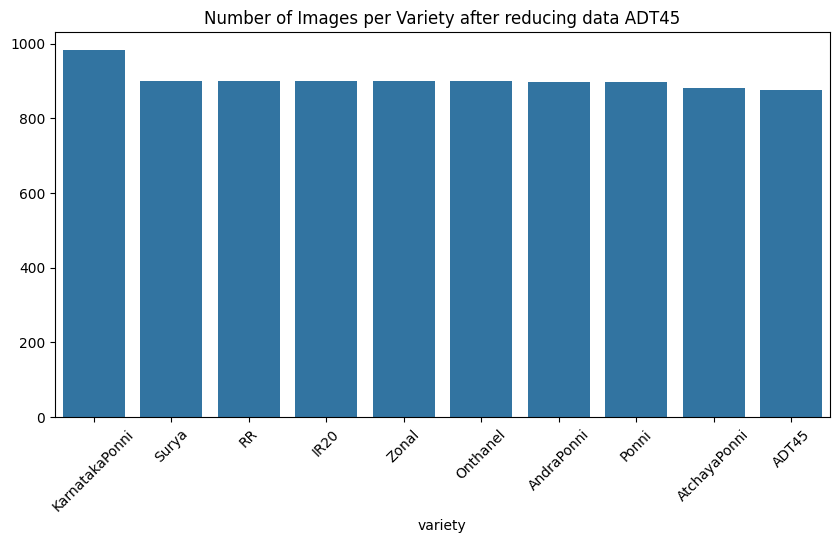

In [ ]:
meta_filtered = pd.read_csv('/content/drive/MyDrive/A2_Machine_Learning/Task 2/meta_train_filtered.csv')

# Variety distribution
variety_counts = meta_filtered['variety'].value_counts()

plt.figure(figsize=(10,5))
sns.barplot(x=variety_counts.index, y=variety_counts.values)
plt.title('Number of Images per Variety after reducing data ADT45')
plt.xticks(rotation=45)
plt.show()

####**4. Display image per label**

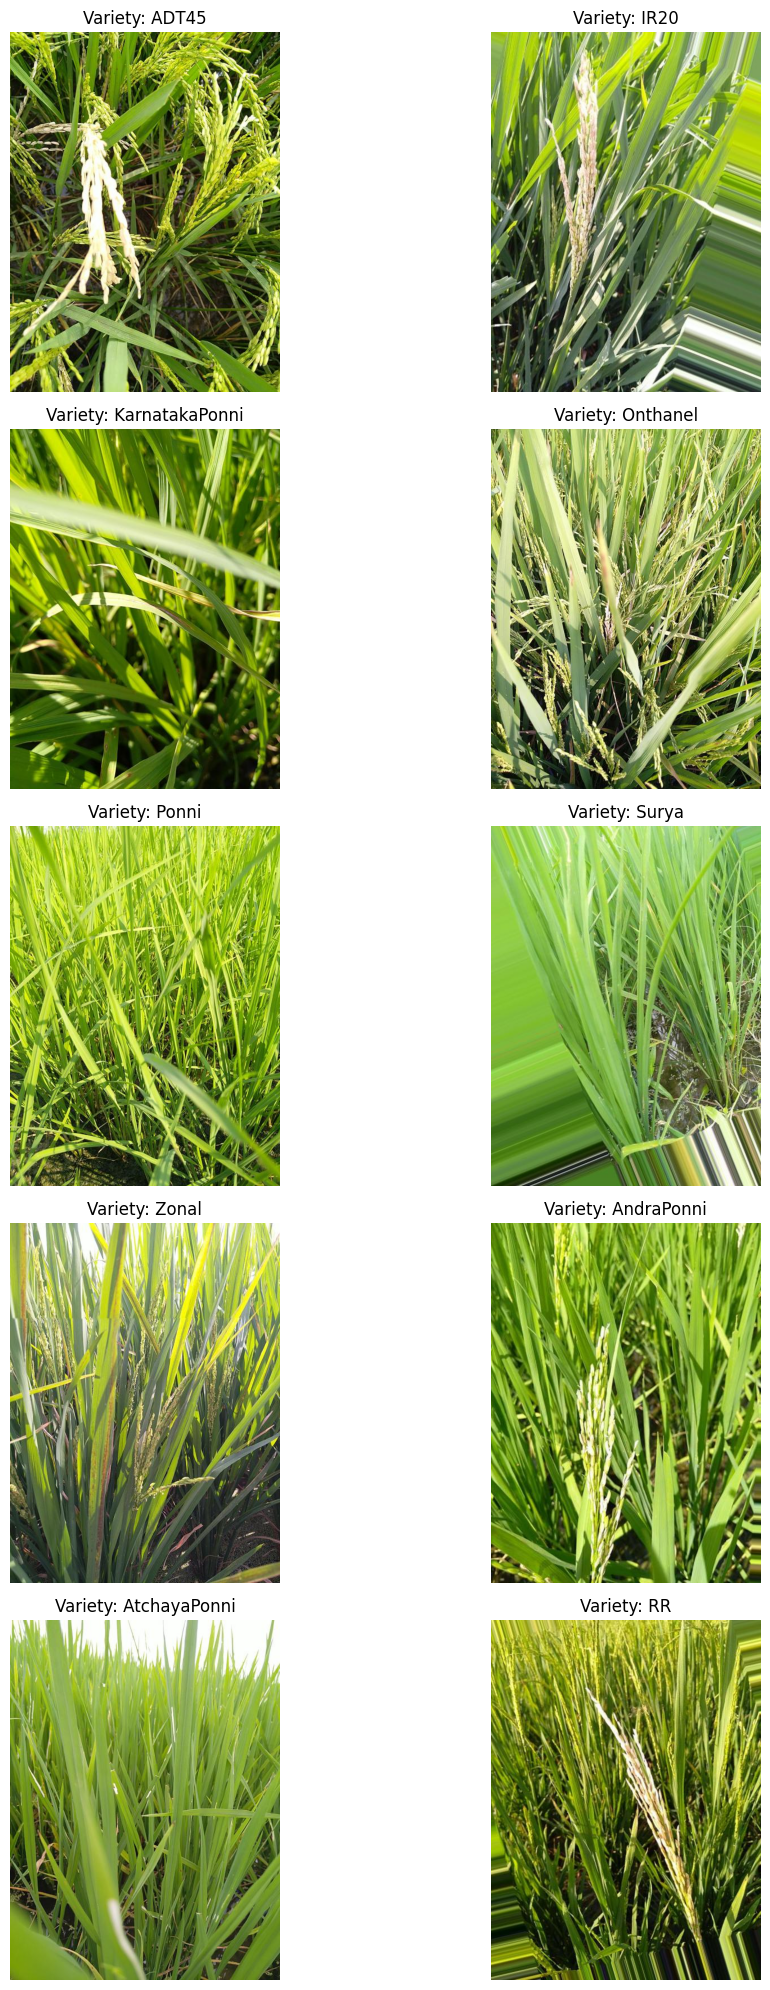

In [ ]:
train_path = '/content/drive/MyDrive/A2_Machine_Learning/Task 2/train_by_variety'

# Convert varieties to lowercase to match folder names
varieties = meta['variety'].unique()

# Plot images
fig, axes = plt.subplots(5,2, figsize=(12,20))
axes = axes.flatten()

for i, variety in enumerate(varieties):
    img_list = glob(os.path.join(train_path, variety, '*.jpg'))

    if len(img_list) == 0:
        print(f"No images found for variety {variety}. Skipping...")
        continue

    img_path = random.choice(img_list)
    img = Image.open(img_path)
    axes[i].imshow(img)
    axes[i].set_title(f"Variety: {variety}")
    axes[i].axis('off')

plt.tight_layout()
plt.show()


####**4.Compare data before and after filtered**

<Figure size 1000x600 with 0 Axes>

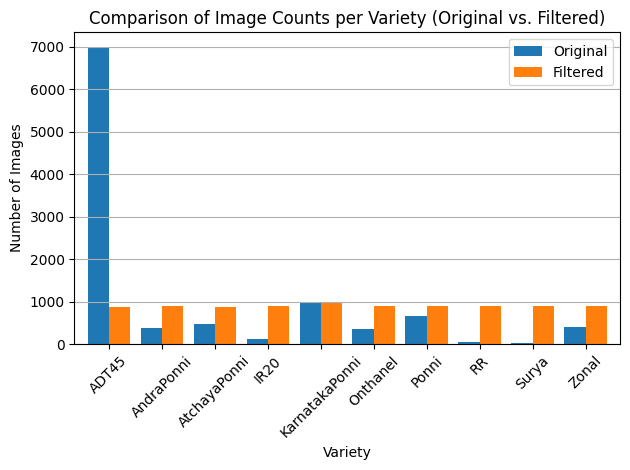

In [ ]:
# Load original and filtered metadata
meta_df = pd.read_csv("/content/drive/MyDrive/A2_Machine_Learning/Task 2/meta_train.csv")
filtered_meta_df = pd.read_csv("/content/drive/MyDrive/A2_Machine_Learning/Task 2/meta_train_filtered.csv")

# Count labels before and after filtering
original_counts = meta_df['variety'].value_counts().sort_index()
filtered_counts = filtered_meta_df['variety'].value_counts().sort_index()

# Combine counts into a single DataFrame for comparison
comparison_df = pd.DataFrame({
    'Original': original_counts,
    'Filtered': filtered_counts
}).fillna(0)

# Plot grouped bar chart
plt.figure(figsize=(10, 6))
comparison_df.plot(kind='bar', width=0.8)
plt.title('Comparison of Image Counts per Variety (Original vs. Filtered)')
plt.ylabel('Number of Images')
plt.xlabel('Variety')
plt.xticks(rotation=45)
plt.tight_layout()
plt.grid(axis='y')
plt.show()


#### **5. Prepare Data for training**

In [ ]:
# Convert class labels to strings (required when using class_mode='categorical')
filtered_meta_df['variety'] = filtered_meta_df['variety'].astype(str)

# Add a new column 'ImgPath' that constructs the relative path to each image
filtered_meta_df['ImgPath'] = filtered_meta_df['variety'] + '/' + filtered_meta_df['image_id']  # e.g., / adt/100123.jpg

# Stratified split to ensure class distribution remains balanced in train and test sets
train_data, test_data = train_test_split(
    filtered_meta_df,
    test_size=0.2,
    stratify=filtered_meta_df['variety'],            # ensures class ratios stay consistent
    random_state=42
)

# ImageDataGenerator for training: apply rescaling and set data format
train_datagen = ImageDataGenerator(
    rescale=1./255,                       # normalize pixel values to [0, 1]
    data_format='channels_last'          # image shape = (height, width, channels)
)

# ImageDataGenerator for validation/test (no augmentation, just rescaling)
val_test_datagen = ImageDataGenerator(
    rescale=1./255,
    data_format='channels_last'
)

# Set common image size and batch size
BATCH_SIZE = 32
IMG_SIZE = (256, 256)  # resizing all input images to 256x256

# Create generator for training data
train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_data,
    directory='/content/drive/MyDrive/A2_Machine_Learning/Task 2/train_by_variety',
    x_col='ImgPath',
    y_col='variety',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True
)

# Create generator for validation data
val_generator = val_test_datagen.flow_from_dataframe(
    dataframe=test_data,
    directory='/content/drive/MyDrive/A2_Machine_Learning/Task 2/train_by_variety',
    x_col='ImgPath',
    y_col='variety',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

Found 7221 validated image filenames belonging to 10 classes.
Found 1806 validated image filenames belonging to 10 classes.


In [ ]:
import matplotlib.pyplot as plt
def plot_learning_curve(train_loss, val_loss, train_metric, val_metric, metric_name='Accuracy'):
    plt.figure(figsize=(10,5))

    plt.subplot(1,2,1)
    plt.plot(train_loss, 'r--')
    plt.plot(val_loss, 'b--')
    plt.xlabel("epochs")
    plt.ylabel("Loss")
    plt.legend(['train', 'val'], loc='upper left')

    plt.subplot(1,2,2)
    plt.plot(train_metric, 'r--')
    plt.plot(val_metric, 'b--')
    plt.xlabel("epochs")
    plt.ylabel(metric_name)
    plt.legend(['train', 'val'], loc='upper left')

    plt.show()

#### **6. Start training**

<ipython-input-23-138c5ac14be5>:28: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=input_shape)


Training Baseline Model...
Epoch 1/50
226/226 ━━━━━━━━━━━━━━━━━━━━ 119s 341ms/step - accuracy: 0.7311 - loss: 0.8426 - val_accuracy: 0.2990 - val_loss: 9.2222 - learning_rate: 0.0010
Epoch 2/50
226/226 ━━━━━━━━━━━━━━━━━━━━ 56s 245ms/step - accuracy: 0.9252 - loss: 0.2367 - val_accuracy: 0.2303 - val_loss: 12.6470 - learning_rate: 0.0010
Epoch 3/50
226/226 ━━━━━━━━━━━━━━━━━━━━ 55s 244ms/step - accuracy: 0.9392 - loss: 0.1853 - val_accuracy: 0.2021 - val_loss: 9.2192 - learning_rate: 0.0010
Epoch 4/50
226/226 ━━━━━━━━━━━━━━━━━━━━ 55s 244ms/step - accuracy: 0.9609 - loss: 0.1330 - val_accuracy: 0.2287 - val_loss: 7.9454 - learning_rate: 0.0010
Epoch 5/50
226/226 ━━━━━━━━━━━━━━━━━━━━ 56s 249ms/step - accuracy: 0.9711 - loss: 0.0884 - val_accuracy: 0.2054 - val_loss: 11.0590 - learning_rate: 0.0010
Epoch 6/50
226/226 ━━━━━━━━━━━━━━━━━━━━ 56s 248ms/step - accuracy: 0.9613 - loss: 0.1214 - val_accuracy: 0.2962 - val_loss: 8.3978 - learning_rate: 0.0010
Epoch 7/50
226/226 ━━━━━━━━━━━━━━━━━━━━ 

Baseline Model saved.


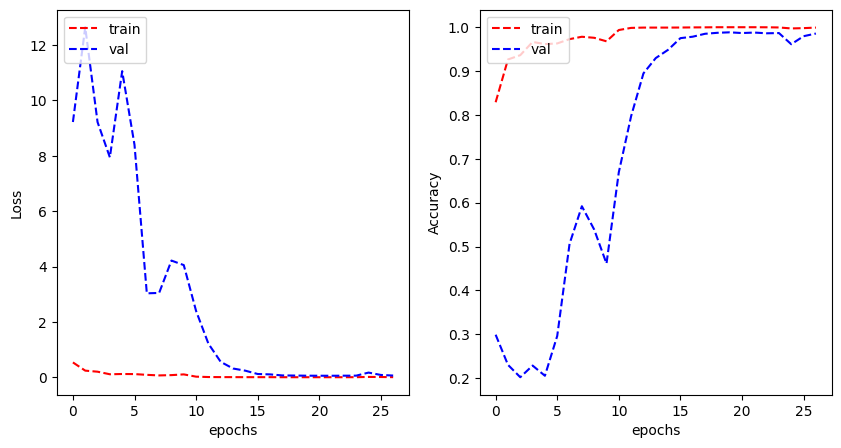

Training Proposed Model...
Epoch 1/50
226/226 ━━━━━━━━━━━━━━━━━━━━ 151s 262ms/step - accuracy: 0.3363 - loss: 2.2422 - val_accuracy: 0.1141 - val_loss: 4.9384 - learning_rate: 1.0000e-04
Epoch 2/50
226/226 ━━━━━━━━━━━━━━━━━━━━ 52s 231ms/step - accuracy: 0.6416 - loss: 1.0450 - val_accuracy: 0.4623 - val_loss: 1.5366 - learning_rate: 1.0000e-04
Epoch 3/50
226/226 ━━━━━━━━━━━━━━━━━━━━ 52s 230ms/step - accuracy: 0.7442 - loss: 0.7498 - val_accuracy: 0.8195 - val_loss: 0.5492 - learning_rate: 1.0000e-04
Epoch 4/50
226/226 ━━━━━━━━━━━━━━━━━━━━ 53s 233ms/step - accuracy: 0.7979 - loss: 0.5895 - val_accuracy: 0.8239 - val_loss: 0.5075 - learning_rate: 1.0000e-04
Epoch 5/50
226/226 ━━━━━━━━━━━━━━━━━━━━ 82s 233ms/step - accuracy: 0.8320 - loss: 0.4866 - val_accuracy: 0.8688 - val_loss: 0.4162 - learning_rate: 1.0000e-04
Epoch 6/50
226/226 ━━━━━━━━━━━━━━━━━━━━ 52s 228ms/step - accuracy: 0.8738 - loss: 0.3660 - val_accuracy: 0.8776 - val_loss: 0.3787 - learning_rate: 1.0000e-04
Epoch 7/50
226/226

proposed model saved.


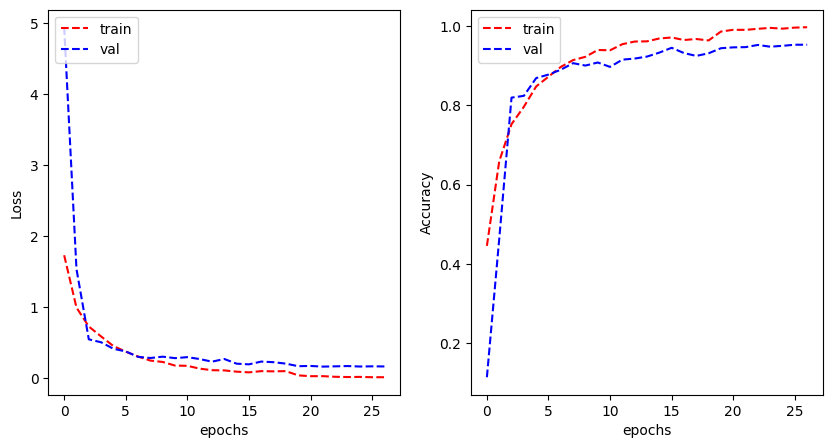

In [ ]:
import os
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import register_keras_serializable
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.optimizers import Adam

# Custom Swish Activation
@register_keras_serializable()
class Swish(tf.keras.layers.Layer):
    def __init__(self, **kwargs):
        super(Swish, self).__init__(**kwargs)

    def call(self, inputs):
        return inputs * tf.sigmoid(inputs)

    def get_config(self):
        config = super(Swish, self).get_config()
        return config


# Baseline Model
def build_baseline_model(input_shape=(256, 256, 3), num_classes=10):
    base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=input_shape)
    base_model.trainable = True  # Fine-tuning

    model = Sequential([
        base_model,
        tf.keras.layers.GlobalAveragePooling2D(),
        Dense(128, activation='relu'),
        Dense(num_classes, activation='softmax')
    ])

    model.compile(optimizer=Adam(),
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model


# Proposed Model
def build_proposed_model(input_shape=(256, 256, 3), num_classes=10):
    inputs = layers.Input(shape=input_shape)

    x = layers.Conv2D(16, (3, 3), padding='same')(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(alpha=0.1)(x)
    x = layers.MaxPooling2D((2, 2))(x)

    x = layers.Conv2D(32, (3, 3), padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(alpha=0.1)(x)
    x = layers.MaxPooling2D((2, 2))(x)

    x = layers.Conv2D(64, (3, 3), padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = Swish()(x)
    x = layers.MaxPooling2D((2, 2))(x)

    x = layers.Conv2D(128, (3, 3), padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = Swish()(x)
    x = layers.MaxPooling2D((2, 2))(x)

    x = layers.Flatten()(x)
    x = layers.Dense(1024, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(128, activation='relu')(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    model = models.Model(inputs, outputs)

    model.compile(optimizer=optimizers.Adam(learning_rate=1e-4),
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model

# Build models
baseline_model = build_baseline_model()
proposed_model = build_proposed_model()

# Train Baseline Model
print("Training Baseline Model...")
history_baseline = baseline_model.fit(
    train_generator,
    epochs=50,
    validation_data=val_generator,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(factor=0.2, patience=3)
    ]
)

# Save Baseline Model
baseline_model.save('baseline_model.h5')
print("Baseline Model saved.")

# After training
train_loss = history_baseline.history['loss']
val_loss = history_baseline.history['val_loss']
train_acc = history_baseline.history['accuracy']
val_acc = history_baseline.history['val_accuracy']

plot_learning_curve(train_loss, val_loss, train_acc, val_acc, metric_name='Accuracy')

# Train Proposed Model
print("Training Proposed Model...")
history_proposed = proposed_model.fit(
    train_generator,
    epochs=50,
    validation_data=val_generator,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(factor=0.2, patience=3)
    ]
)

# Save Proposed Model
proposed_model.save('/content/drive/MyDrive/A2_Machine_Learning/Task 2/proposed_model_TASK2.h5')
print("proposed model saved.")

# After training
train_loss = history_proposed.history['loss']
val_loss = history_proposed.history['val_loss']
train_acc = history_proposed.history['accuracy']
val_acc = history_proposed.history['val_accuracy']

plot_learning_curve(train_loss, val_loss, train_acc, val_acc, metric_name='Accuracy')

#### 7**. Export prediction csv file**

In [1]:
import os
import numpy as np
import pandas as pd
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import tensorflow as tf

# === Re-define the custom Swish layer ===
@tf.keras.utils.register_keras_serializable()
class Swish(tf.keras.layers.Layer):
    def __init__(self, **kwargs):
        super(Swish, self).__init__(**kwargs)

    def call(self, inputs):
        return inputs * tf.sigmoid(inputs)

    def get_config(self):
        config = super(Swish, self).get_config()
        return config

# === Load the trained model with custom_objects ===
model = load_model(
    '/content/drive/MyDrive/A2_Machine_Learning/Task 2/proposed_model_TASK2.h5',
    custom_objects={'Swish': Swish}
)

# === Constants ===
IMG_SIZE = 256  # Change this based on your model input size
IMAGE_DIR = '/content/drive/MyDrive/A2_Machine_Learning/Task 2/test_images/test_images'

# === Load and preprocess test images ===
image_ids = sorted([f for f in os.listdir(IMAGE_DIR) if f.endswith('.jpg')])
X = []

for image_id in image_ids:
    img_path = os.path.join(IMAGE_DIR, image_id)
    img = load_img(img_path, target_size=(IMG_SIZE, IMG_SIZE))
    img_array = img_to_array(img) / 255.0
    X.append(img_array)

X = np.array(X)

CLASS_LABELS = ['ADT45', 'AndraPonni', 'AtchayaPonni', 'IR20', 'KarnatakaPonni', 'Onthanel', 'Ponni', 'RR', 'Surya', 'Zonal']

# === Predict ===
preds = model.predict(X)
predicted_indices = [CLASS_LABELS[np.argmax(p)] for p in preds]

# === Save to CSV ===
df = pd.DataFrame({
    'image_id': image_ids,
    'prediction_index': predicted_indices
})

df.to_csv('/content/drive/MyDrive/A2_Machine_Learning/Task 2/task2_predictions.csv', index=False)
print("✅ Prediction file saved as: /content/drive/MyDrive/A2_Machine_Learning/Task 2/task2_predictions.csv")

FileNotFoundError: [Errno 2] Unable to synchronously open file (unable to open file: name = '/content/drive/MyDrive/A2_Machine_Learning/Task 2/proposed_model_TASK2.h5', errno = 2, error message = 'No such file or directory', flags = 0, o_flags = 0)